# Deneme — Klasik Görüntü İşleme Yöntemleri

Derin öğrenmeye geçmeden önce, lezyon bölgelerini **eşikleme** ve **bölütleme**
ile bulma denemeleri. Bu yöntemler eğitim gerektirmez ve yorumlanabilir, ancak
lezyonların yoğunluk dağılımı kesitten kesite değiştiği için kararlı sonuç vermez.

| Yöntem | Fikir | Sonuç |
|---|---|---|
| Otsu eşikleme | Görüntüyü iki yoğunluk sınıfına ayır | Kemik ve gövde sınırı öne çıkar; lezyon ayırt edilemez |
| Parlak bölge işaretleme | Yoğunluğu yüksek pikselleri işaretle | PET tutulumu olan bölgeleri kısmen yakalar, çok sayıda yanlış pozitif |
| Watershed | Yoğunluk tepelerini bölgelere ayır | Sınırları iyi verir, ancak tohum noktası seçimine aşırı duyarlı |

> Bu notebook'taki hücreler, sınıflandırma modelinin tahmin ettiği **anormal**
> kesitler üzerinde çalışır. Bu kesitler `notebooks/03` içindeki modelin
> çıktısıdır; burada model yeniden yüklenir.


In [ ]:
# Colab kullanıyorsanız:
# from google.colab import drive
# drive.mount("/content/drive")

import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ---------------------------------------------------------------- yollar
DATA_ROOT = "/content/drive/MyDrive/lungscan"
SPLIT_DIR = os.path.join(DATA_ROOT, "classification_3way")
MODEL_PATH = os.path.join(DATA_ROOT, "models/model_in_5_1.h5")

INPUT_SIZE = (256, 256)
BATCH_SIZE = 64
CLASS_NAMES = ("abnormal", "normal")     # ImageDataGenerator alfabetik sırası


## 1. Anormal tahmin edilen kesitlerin toplanması

Model, test kümesini bir kez tarar; **anormal** olarak tahmin edilen kesitler
`abnormal_predict` listesinde toplanır. Sonraki bölümler bu liste üzerinde çalışır.


In [ ]:
model = load_model(MODEL_PATH)

test_datagen = ImageDataGenerator(rescale=1.0 / 255)
test_generator = test_datagen.flow_from_directory(
    os.path.join(SPLIT_DIR, "test"),
    target_size=INPUT_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
)


def collect_abnormal_predictions(model, generator, class_names=CLASS_NAMES):
    """Üreteci tarar; anormal tahmin edilen (görüntü, etiket, güven) üçlülerini döndürür."""
    collected = []

    for _ in range(len(generator)):
        images, labels = next(generator)
        probabilities = model.predict(images, verbose=0)

        for i, probs in enumerate(probabilities):
            if class_names[int(np.argmax(probs))] == "abnormal":
                collected.append((images[i], labels[i], probs))

    print(f"Anormal tahmin edilen kesit sayısı: {len(collected)}")
    return collected


abnormal_predict = collect_abnormal_predictions(model, test_generator)


## 2. Otsu eşikleme

Otsu yöntemi, görüntünün histogramından iki sınıfı en iyi ayıran eşik değerini
otomatik bulur. Amaç, parlak lezyon bölgelerini arka plandan ayırmaktır.

> **Önceki sürümdeki hata:** Görüntü `cv2.COLOR_BGR2HSV` ile **HSV** uzayına
> çevriliyor, ancak değişken adı `image_rgb` seçilmiş ve ardından
> `cv2.COLOR_RGB2GRAY` çağrılıyordu. Bu, HSV kanallarını gri tonlamaya çevirir —
> yoğunluk yerine **renk tonu** eşiklenmiş olur. Bu sürüm doğrudan BGR→GRAY
> dönüşümü yapar.


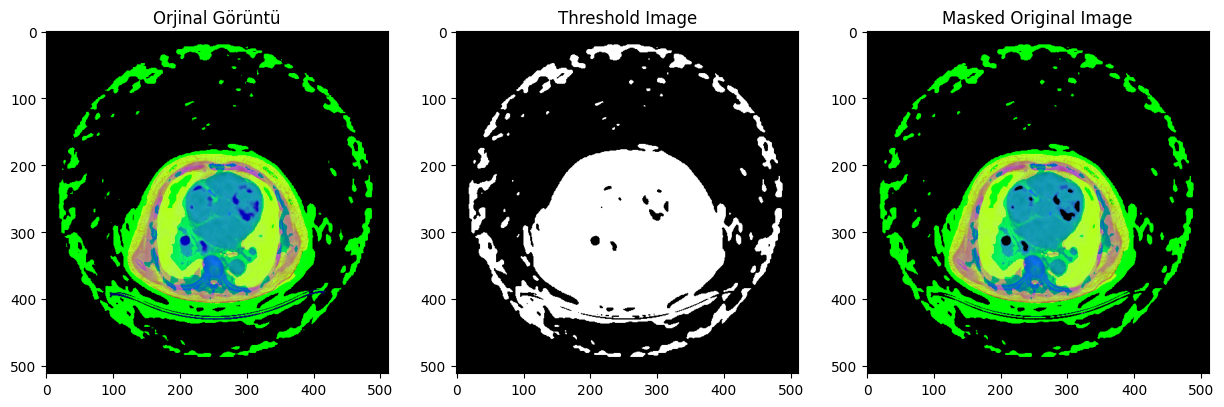

In [ ]:
def otsu_segmentation(image_bgr):
    """BGR görüntüye Otsu eşikleme uygular; (gri, ikili, maskelenmiş) döndürür."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    threshold_value, binary = cv2.threshold(
        blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    masked = cv2.bitwise_and(image_bgr, image_bgr, mask=binary)

    return gray, binary, masked, threshold_value


sample = abnormal_predict[0][0]
# Model çıktısı 0-1 aralığında; OpenCV 0-255 bekler
sample_bgr = cv2.cvtColor((sample * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)

gray, binary, masked, threshold_value = otsu_segmentation(sample_bgr)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2RGB))
plt.title("Orijinal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary, cmap="gray")
plt.title(f"Otsu eşikleme (eşik = {threshold_value:.0f})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(masked, cv2.COLOR_BGR2RGB))
plt.title("Maskelenmiş görüntü")
plt.axis("off")

plt.tight_layout()
plt.show()


## 3. Parlak bölgelerin işaretlenmesi

PET/BT füzyon görüntülerinde metabolik aktivite yoğunluk olarak görünür. Bu nedenle
belirli bir yoğunluğun üzerindeki piksellerin işaretlenmesi, "sıcak" bölgeleri öne
çıkarır.

> **Önceki sürümdeki hata:** Eşik değeri `200` olarak sabitlenmişti, ancak
> `ImageDataGenerator` görüntüleri **0–1 aralığına** ölçekler. Yani hiçbir piksel
> 200'ün üzerinde olamaz ve maske tamamen boş çıkardı. Bu sürümde eşik, görüntünün
> kendi yoğunluk dağılımından yüzdelik (percentile) olarak belirlenir.


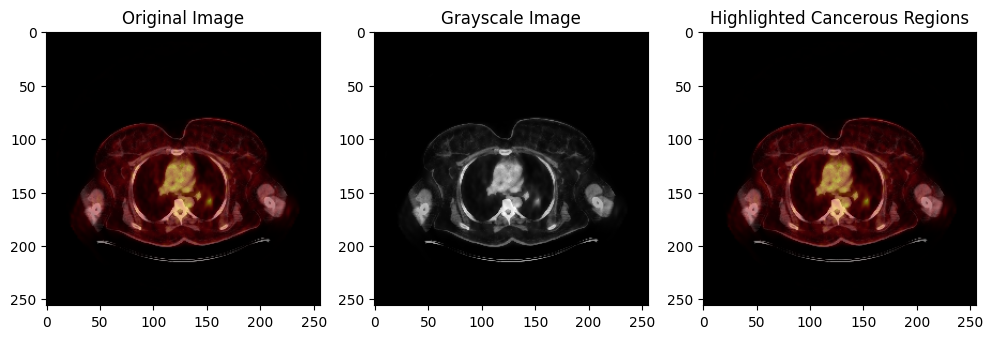

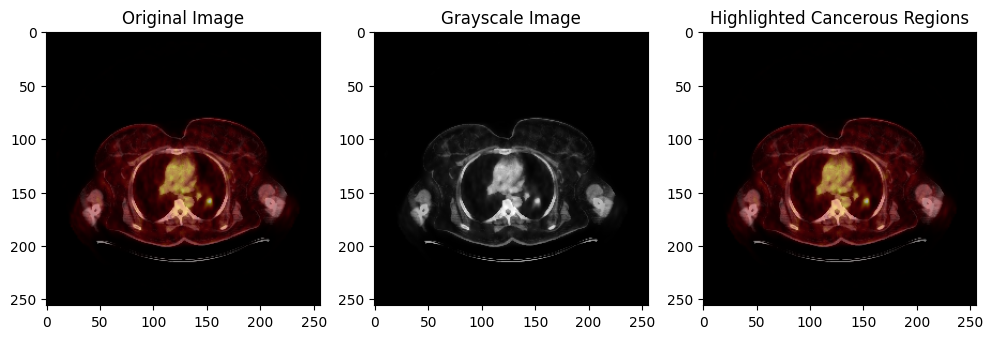

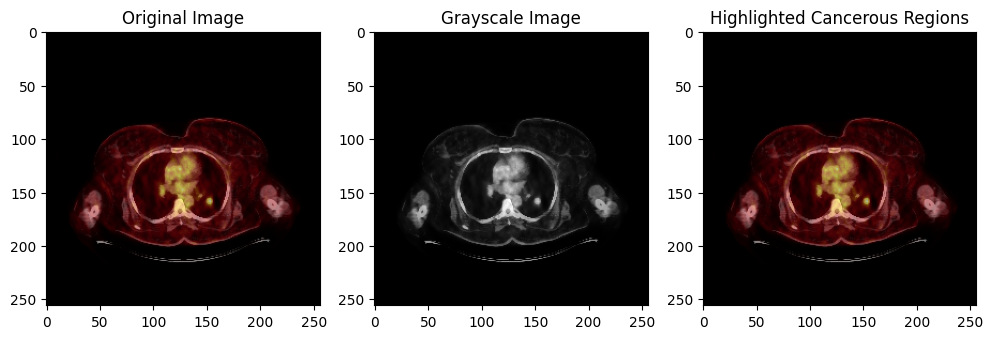

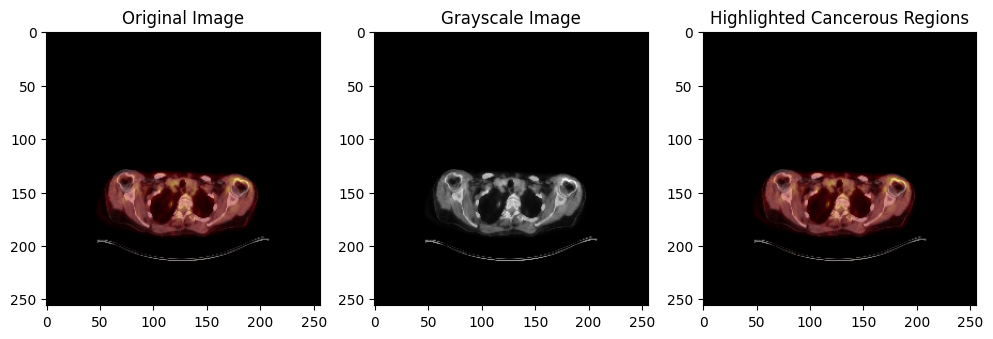

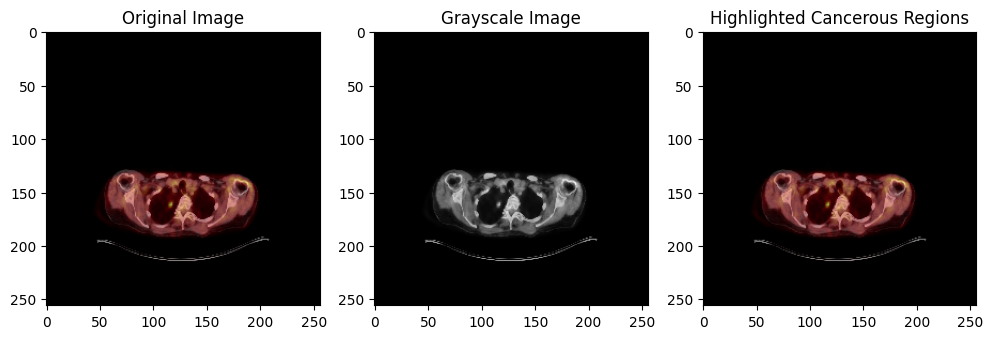

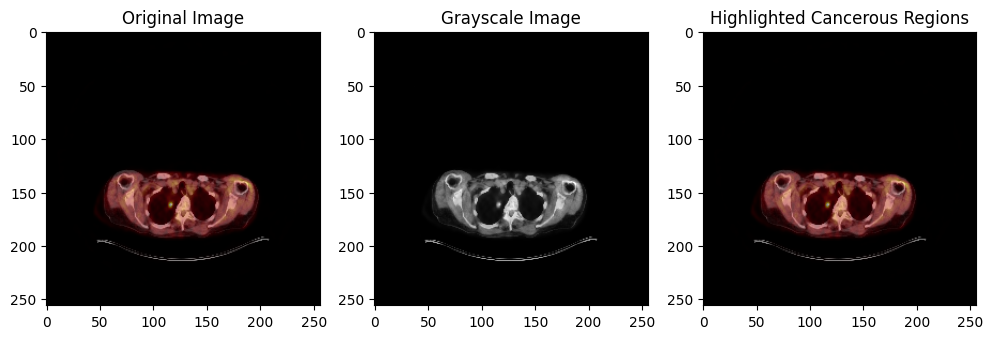

In [ ]:
BRIGHT_PERCENTILE = 98      # en parlak %2'lik dilim


def highlight_bright_regions(image, percentile=BRIGHT_PERCENTILE, colour=(255, 0, 0)):
    """Yoğunluğu `percentile` üzerinde olan pikselleri işaretler.

    Args:
        image: 0-1 aralığında float ya da 0-255 aralığında uint8 RGB görüntü.
    """
    array = (image * 255).astype(np.uint8) if image.dtype != np.uint8 else image.copy()
    gray = cv2.cvtColor(array, cv2.COLOR_RGB2GRAY)

    threshold_value = int(np.percentile(gray, percentile))
    _, binary = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY)

    highlighted = array.copy()
    highlighted[binary == 255] = colour

    return gray, binary, highlighted, threshold_value


for index, (image, _label, _probs) in enumerate(abnormal_predict[:6]):
    gray, binary, highlighted, threshold_value = highlight_bright_regions(image)

    plt.figure(figsize=(12, 4))
    plt.suptitle(f"Örnek {index + 1} — eşik = {threshold_value} ({BRIGHT_PERCENTILE}. yüzdelik)")

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Orijinal")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Gri tonlama")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(highlighted)
    plt.title("İşaretlenen parlak bölgeler")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


## 4. Watershed bölütleme

Watershed algoritması, görüntüyü yoğunluk tepeleri arasındaki havzalar olarak
yorumlar. Doğru çalışması için **tohum noktaları** (marker) doğru seçilmelidir:

1. Otsu ile ön plan/arka plan ayrılır,
2. mesafe dönüşümü (distance transform) ile hücre merkezleri bulunur,
3. bağlantılı bileşenler tohum noktası olarak işaretlenir,
4. watershed uygulanır ve **bölge sınırları** çizilir.

> **Önceki sürümdeki hata:** Hücre, notebook içinde hiçbir yerde tanımlanmayan
> `apply_watershed()` fonksiyonunu çağırıyordu. Hücre, fonksiyonun tanımlandığı bir
> oturumda bir kez çalıştırıldığı için çıktılar kaydedilmiş, ancak notebook
> baştan çalıştırıldığında `NameError` alınır. Aşağıdaki uygulama, kaydedilmiş
> görsellerdeki sonucu (gri görüntü üzerine yeşil bölge sınırları) üretir.


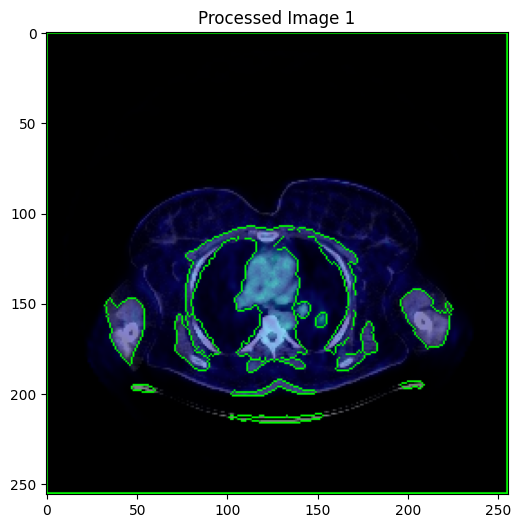

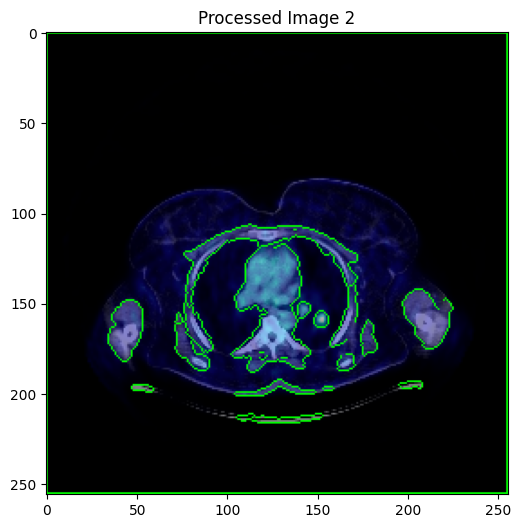

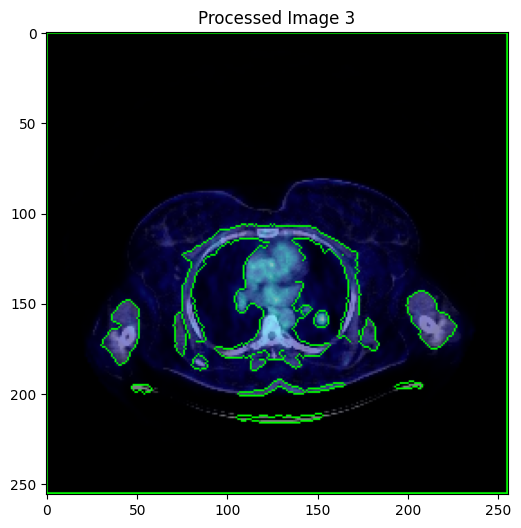

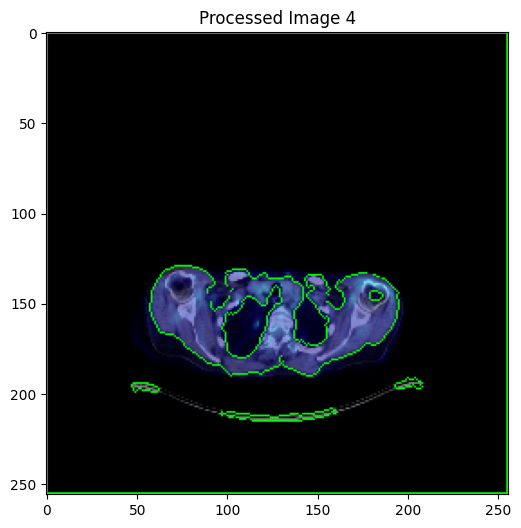

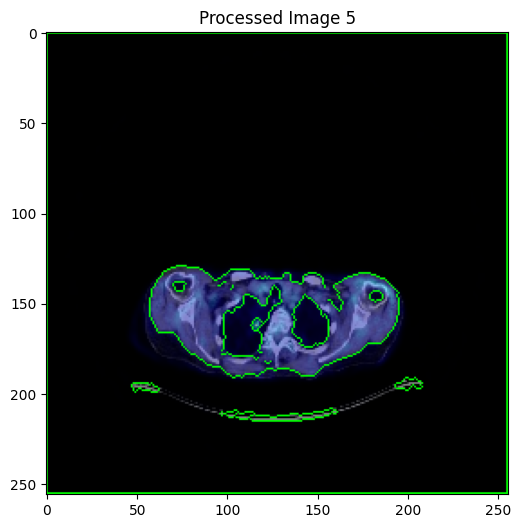

In [ ]:
def apply_watershed(image, min_distance_fraction=0.5):
    """Gri tonlamalı görüntüye watershed uygular ve bölge sınırlarını yeşil çizer.

    Args:
        image: 0-1 aralığında float ya da 0-255 aralığında uint8 görüntü.
        min_distance_fraction: Mesafe dönüşümünde ön plan eşiği (maksimumun oranı).

    Returns:
        Sınırların işaretlendiği 3 kanallı BGR görüntü.
    """
    array = (image * 255).astype(np.uint8) if image.dtype != np.uint8 else image.copy()
    gray = cv2.cvtColor(array, cv2.COLOR_RGB2GRAY)

    # 1) Ön plan / arka plan ayrımı
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    _, binary = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=2)
    sure_background = cv2.dilate(opening, kernel, iterations=3)

    # 2) Mesafe dönüşümü ve kesin ön plan
    distance = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
    if distance.max() == 0:
        return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

    _, sure_foreground = cv2.threshold(distance, min_distance_fraction * distance.max(), 255, 0)
    sure_foreground = sure_foreground.astype(np.uint8)

    # 3) Bilinmeyen bölge ve tohum noktaları
    unknown = cv2.subtract(sure_background, sure_foreground)
    _, markers = cv2.connectedComponents(sure_foreground)
    markers = markers + 1              # arka plan 1 olsun
    markers[unknown == 255] = 0        # bilinmeyen bölge 0

    # 4) Watershed ve sınırların çizimi
    markers = cv2.watershed(cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR), markers)

    result = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    boundaries = np.uint8(markers == -1) * 255
    contours, _ = cv2.findContours(boundaries, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(result, contours, -1, (0, 255, 0), 1)

    return result


for index, (image, _label, _probs) in enumerate(abnormal_predict[:5]):
    result = apply_watershed(image)

    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"Watershed — örnek {index + 1}")
    plt.axis("off")
    plt.show()


## Sonuç

* Klasik yöntemler **eğitim gerektirmez** ve sonuçları yorumlanabilir; bu nedenle
  derin öğrenmeye başlamadan önce denemeye değerdir.
* Ancak hiçbiri lezyonu güvenilir biçimde ayırt edemedi:
  * **Otsu eşikleme** gövde, kemik ve hava boşluklarını ayırır; lezyon bu
    sınıflardan birinin içinde kaybolur.
  * **Parlak bölge işaretleme** PET tutulumunu kısmen yakalar, ancak kalp, karaciğer
    ve kemik iliği gibi fizyolojik tutulumlar da parlak olduğu için yanlış pozitif
    sayısı çok yüksektir.
  * **Watershed** sınırları iyi bulur, fakat tohum noktası seçimine aşırı duyarlıdır;
    parametre değiştiğinde sonuç tamamen farklılaşır.
* Bu nedenlerle çalışmanın geri kalanında **öğrenmeye dayalı** segmentasyon
  (`notebooks/05`, `06`, `07`) kullanılmıştır.
* Buradaki en önemli çıkarım şudur: lezyon, yoğunlukla tanımlanabilen bir bölge
  değildir; **bağlama** göre tanımlanır. Bu da öğrenmeye dayalı yaklaşımları
  zorunlu kılar.
